# Classifying Heart Disease with Logistic Regression

Binary classification on the Cleveland heart disease dataset: 303 patients, 13 predictors, and a target recording whether heart disease is present.

This notebook is about logistic regression specifically, which means two things get taken seriously that a pure accuracy chase would skip. First, **the coefficients are the output**, not a by-product: a logistic model that cannot be read is a worse version of a model that does not need to be. Second, **the encoding has to respect what each variable actually is**. Four of the predictors are nominal categories stored as integers, and feeding them in as numbers tells the model that `thal=7` is more than twice `thal=3` when the two are unordered clinical findings. Section 4 measures what that mistake costs.

**Codebook**, which matters because the column names give nothing away:

| Column | Meaning | Type |
|---|---|---|
| `age` | Age in years | continuous |
| `sex` | 1 = male, 0 = female | binary |
| `cp` | Chest pain: 1 typical angina, 2 atypical angina, 3 non-anginal, 4 asymptomatic | **nominal** |
| `trestbps` | Resting blood pressure (mmHg) | continuous |
| `chol` | Serum cholesterol (mg/dL) | continuous |
| `fbs` | Fasting blood sugar > 120 mg/dL | binary |
| `restecg` | Resting ECG: 0 normal, 1 ST-T abnormality, 2 left ventricular hypertrophy | **nominal** |
| `thalach` | Maximum heart rate achieved | continuous |
| `exang` | Exercise-induced angina | binary |
| `oldpeak` | ST depression induced by exercise | continuous |
| `slope` | ST segment slope: 1 upsloping, 2 flat, 3 downsloping | ordinal |
| `ca` | Number of major vessels coloured by fluoroscopy (0 to 3) | ordinal count |
| `thal` | Thalassemia scan: 3 normal, 6 fixed defect, 7 reversible defect | **nominal** |
| `present` | Heart disease present (target) | binary |

Note the coding of `thal`: the values are 3, 6 and 7. There is no sense in which those gaps are meaningful, which is the clearest illustration of the problem.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('pandas      ', pd.__version__)
print('numpy       ', np.__version__)
print('scikit-learn', sklearn.__version__)

pandas       2.2.2
numpy        1.26.4
scikit-learn 1.4.2


## 1. Loading the data correctly

Two things need handling at read time. The file is an R export, so column one is an unnamed row index that `read_csv` would otherwise keep as a feature called `Unnamed: 0`. And missing values are recorded as the string `?`, which would silently force `ca` and `thal` to object dtype and then crash or mis-encode downstream. Both are fixed with arguments rather than with cleanup code afterwards.

In [24]:
heart = pd.read_csv('heart_disease.csv', index_col=0, na_values='?')
print('Shape:', heart.shape)
print('Index name:', heart.index.name, '(the R row numbers, kept out of the feature matrix)')
heart.head()

Shape: (303, 14)
Index name: None (the R row numbers, kept out of the feature matrix)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,present
1,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
2,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
3,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
4,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
5,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [25]:
heart.info()

<class 'pandas.core.frame.DataFrame'>
Index: 303 entries, 1 to 303
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  present   303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 35.5 KB


In [26]:
heart.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## 2. Missing values

Six values across two columns. With 303 patients that is 2% of rows, small enough that dropping them is tempting and still the wrong default: the pipeline can impute them on training folds only at no cost, which keeps every row and avoids an assumption that the missingness is random.

In [27]:
print('Missing values per column:')
miss = heart.isnull().sum()
print(miss[miss > 0])
print()
print('Rows with any missing value:', int(heart.isnull().any(axis=1).sum()), 'of', len(heart),
      '(' + str(round(100 * heart.isnull().any(axis=1).mean(), 1)) + '%)')
print()
print('The affected rows:')
print(heart[heart.isnull().any(axis=1)][['age', 'sex', 'cp', 'ca', 'thal', 'present']])
print()
print('Heart disease rate among rows with a missing value:',
      round(heart.loc[heart.isnull().any(axis=1), 'present'].mean(), 4))
print('Heart disease rate overall:                        ', round(heart['present'].mean(), 4))
print('(too few rows to read anything into this, but worth checking before discarding them)')

Missing values per column:
ca      4
thal    2
dtype: int64

Rows with any missing value: 6 of 303 (2.0%)

The affected rows:
     age  sex  cp   ca  thal  present
88    53    0   3  0.0   NaN        0
167   52    1   3  NaN   3.0        0
193   43    1   4  NaN   7.0        1
267   52    1   4  0.0   NaN        1
288   58    1   2  NaN   7.0        0
303   38    1   3  NaN   3.0        0

Heart disease rate among rows with a missing value: 0.3333
Heart disease rate overall:                         0.4587
(too few rows to read anything into this, but worth checking before discarding them)


In [28]:
counts = heart['present'].value_counts().sort_index()
print('Target balance:')
for v in counts.index:
    label = 'Heart disease present' if v == 1 else 'No heart disease'
    print('  ' + str(v) + ' (' + label + '): ' + str(counts[v]) + '  (' + str(round(100 * counts[v] / len(heart), 1)) + '%)')
print()
print('Majority-class baseline accuracy:', round(counts.max() / len(heart), 4))
print('Reasonably balanced, so accuracy is not actively misleading here, unlike in a rare-event problem.')

Target balance:
  0 (No heart disease): 164  (54.1%)
  1 (Heart disease present): 139  (45.9%)

Majority-class baseline accuracy: 0.5413
Reasonably balanced, so accuracy is not actively misleading here, unlike in a rare-event problem.


## 3. Exploratory analysis

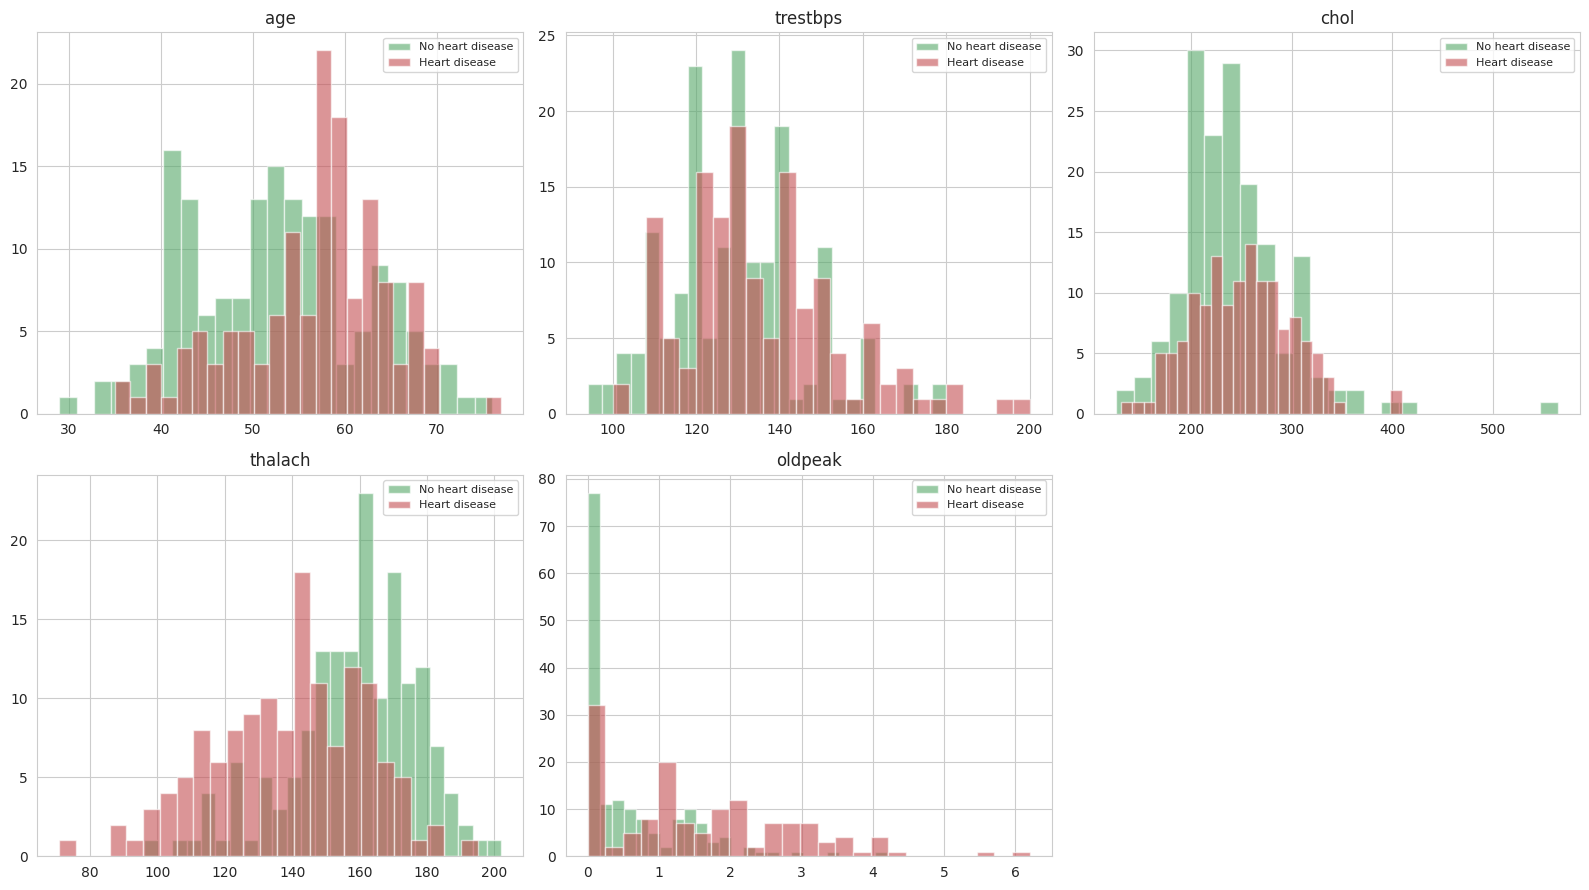

Mean of each continuous predictor by outcome:
present        0       1
age        52.59   56.63
trestbps  129.25  134.57
chol      242.64  251.47
thalach   158.38  139.26
oldpeak     0.59    1.57


In [29]:
continuous = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), continuous):
    for target, colour, label in [(0, '#55A868', 'No heart disease'), (1, '#C44E52', 'Heart disease')]:
        ax.hist(heart.loc[heart['present'] == target, col].dropna(), bins=25, alpha=0.6, color=colour, label=label)
    ax.set_title(col)
    ax.legend(fontsize=8)
axes.flatten()[-1].set_visible(False)
plt.tight_layout()
plt.show()

print('Mean of each continuous predictor by outcome:')
print(heart.groupby('present')[continuous].mean().round(2).T)

In [30]:
coded = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

for col in coded:
    tbl = heart.groupby(col)['present'].agg(['mean', 'count'])
    tbl.columns = ['heart_disease_rate', 'n']
    tbl['heart_disease_rate'] = tbl['heart_disease_rate'].round(3)
    print(col)
    print(tbl)
    print()

sex
     heart_disease_rate    n
sex                         
0                 0.258   97
1                 0.553  206

cp
    heart_disease_rate    n
cp                         
1                0.304   23
2                0.180   50
3                0.209   86
4                0.729  144

fbs
     heart_disease_rate    n
fbs                         
0                 0.453  258
1                 0.489   45

restecg
         heart_disease_rate    n
restecg                         
0                     0.371  151
1                     0.750    4
2                     0.541  148

exang
       heart_disease_rate    n
exang                         
0                   0.309  204
1                   0.768   99

slope
       heart_disease_rate    n
slope                         
1                   0.254  142
2                   0.650  140
3                   0.571   21

ca
     heart_disease_rate    n
ca                          
0.0               0.261  176
1.0               0.677   65


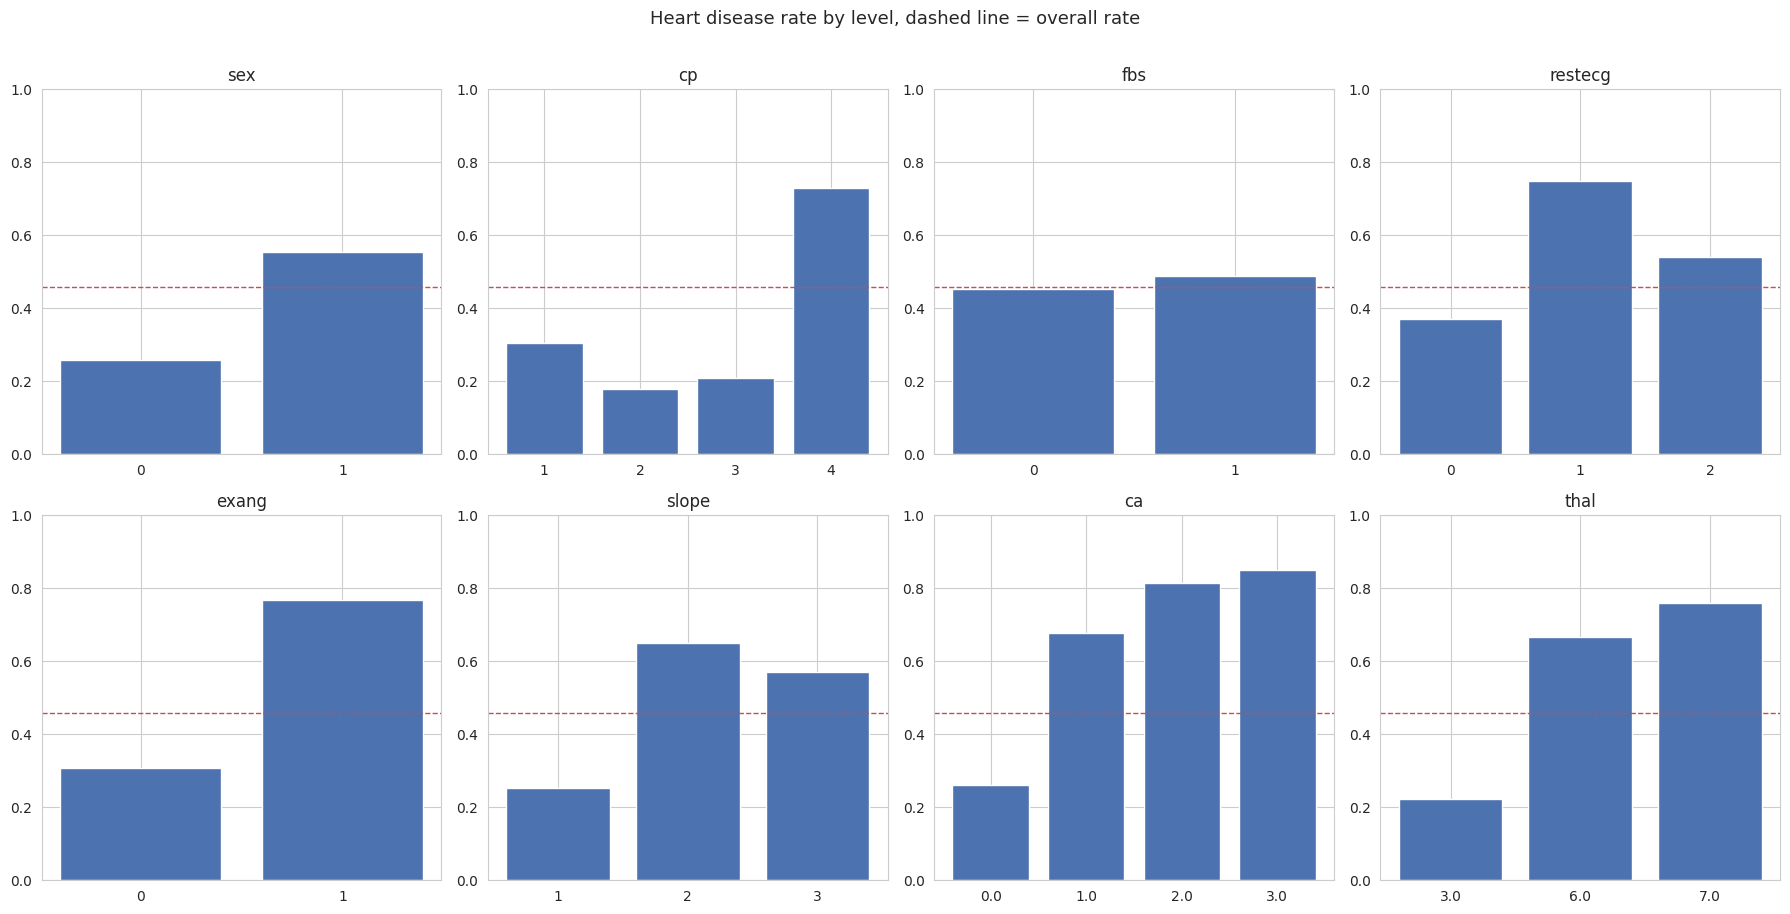

In [31]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, col in zip(axes.flatten(), coded):
    rate = heart.groupby(col)['present'].mean()
    ax.bar([str(i) for i in rate.index], rate.values, color='#4C72B0')
    ax.axhline(heart['present'].mean(), color='#C44E52', linestyle='--', linewidth=1)
    ax.set_ylim(0, 1)
    ax.set_title(col)
plt.suptitle('Heart disease rate by level, dashed line = overall rate', y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

## 4. The encoding question, measured rather than asserted

The codebook says `cp`, `restecg` and `thal` are nominal, so the textbook move is to one-hot encode them and move on. Before doing that it is worth checking what the data says, because the cost of a wrong encoding is a model forced to fit a straight line through a relationship that is not one, and the cost of one-hot encoding is extra parameters estimated from 303 rows.

The cell below measures monotonicity: whether the heart disease rate rises or falls steadily across each column's levels. A column that is monotonic can be represented tolerably by a single coefficient even if it is nominal in principle. A column that is not cannot be, whatever the codebook says.

The results are worth reading carefully, because they do not match the codebook.

In [32]:
print('Is the heart disease rate monotonic across each column\'s levels?')
print()
for col in coded:
    rates = heart.groupby(col)['present'].mean()
    diffs = np.diff(rates.values)
    mono = bool(np.all(diffs >= 0) or np.all(diffs <= 0))
    direction = 'increasing' if np.all(diffs >= 0) else ('decreasing' if np.all(diffs <= 0) else 'NOT monotonic')
    print(col.ljust(9) + ' levels=' + str(len(rates)).ljust(3) +
          ' rates=' + str(np.round(rates.values, 3)).ljust(34) +
          ' ' + direction)
print()
print('Columns flagged NOT monotonic cannot be honestly represented by a single linear coefficient.')

Is the heart disease rate monotonic across each column's levels?

sex       levels=2   rates=[0.258 0.553]                      increasing
cp        levels=4   rates=[0.304 0.18  0.209 0.729]          NOT monotonic
fbs       levels=2   rates=[0.453 0.489]                      increasing
restecg   levels=3   rates=[0.371 0.75  0.541]                NOT monotonic
exang     levels=2   rates=[0.309 0.768]                      increasing
slope     levels=3   rates=[0.254 0.65  0.571]                NOT monotonic
ca        levels=4   rates=[0.261 0.677 0.816 0.85 ]          increasing
thal      levels=3   rates=[0.223 0.667 0.761]                increasing

Columns flagged NOT monotonic cannot be honestly represented by a single linear coefficient.


### The data disagrees with the codebook

Two discrepancies fall out of that table.

`slope` was listed as ordinal, and upsloping to flat to downsloping is a genuine ordering, but the heart disease rate across those three levels is **not** monotonic. Flat carries higher risk than downsloping, so a single coefficient cannot represent it. By the measurement it belongs with the one-hot columns, which the codebook reading would have missed.

`thal` was listed as nominal, and clinically it is: normal, fixed defect and reversible defect are not points on a scale. Yet the rate across its levels rises steadily, so a single coefficient would fit it reasonably well by accident. The numeric coding is still indefensible on its own terms, since the values are 3, 6 and 7 and those gaps mean nothing, but the monotonicity means the practical cost may be small.

So there are two defensible lists of columns to one-hot encode, one from the codebook and one from the data, and they disagree. Rather than pick on authority, all four combinations are fitted below on identical folds.

In [33]:
y = heart['present']
base = heart.drop(columns=['present'])

treatments = {
    'A: all coded columns numeric': [],
    'B: codebook nominal (cp, restecg, thal)': ['cp', 'restecg', 'thal'],
    'C: empirically non-monotonic (cp, restecg, slope)': ['cp', 'restecg', 'slope'],
    'D: every multi-level coded column': ['cp', 'restecg', 'slope', 'thal']
}

matrices = {}
for name, cols in treatments.items():
    Xv = pd.get_dummies(base, columns=cols, drop_first=True) if cols else base.copy()
    matrices[name] = Xv.astype(float)
    print(name)
    print('  features:', Xv.shape[1], ' one-hot:', cols if cols else 'none')

A: all coded columns numeric
  features: 13  one-hot: none
B: codebook nominal (cp, restecg, thal)
  features: 17  one-hot: ['cp', 'restecg', 'thal']
C: empirically non-monotonic (cp, restecg, slope)
  features: 17  one-hot: ['cp', 'restecg', 'slope']
D: every multi-level coded column
  features: 18  one-hot: ['cp', 'restecg', 'slope', 'thal']


In [34]:
from sklearn.model_selection import RepeatedStratifiedKFold

def make_pipeline(model):
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('model', model)
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=6, random_state=RANDOM_STATE)

rows = []
for name, Xv in matrices.items():
    pipe = make_pipeline(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    auc = cross_val_score(pipe, Xv, y, cv=rcv, scoring='roc_auc')
    acc = cross_val_score(pipe, Xv, y, cv=rcv, scoring='accuracy')
    rows.append({'treatment': name, 'features': Xv.shape[1],
                 'auc_mean': round(auc.mean(), 4), 'auc_std': round(auc.std(), 4),
                 'acc_mean': round(acc.mean(), 4), 'acc_std': round(acc.std(), 4)})

enc = pd.DataFrame(rows).set_index('treatment')
print('30 folds each (5-fold cross-validation repeated 6 times), identical folds across treatments:')
print(enc.to_string())

30 folds each (5-fold cross-validation repeated 6 times), identical folds across treatments:
                                                   features  auc_mean  auc_std  acc_mean  acc_std
treatment                                                                                        
A: all coded columns numeric                             13    0.9054   0.0361    0.8371   0.0409
B: codebook nominal (cp, restecg, thal)                  17    0.9074   0.0320    0.8365   0.0440
C: empirically non-monotonic (cp, restecg, slope)        17    0.9090   0.0332    0.8360   0.0469
D: every multi-level coded column                        18    0.9084   0.0328    0.8349   0.0469


In [35]:
best_name = enc['auc_mean'].idxmax()
worst_name = enc['auc_mean'].idxmin()
margin = enc.loc[best_name, 'auc_mean'] - enc.loc[worst_name, 'auc_mean']
typical_noise = enc['auc_std'].mean()

print('Highest mean AUC:', best_name, '=', enc.loc[best_name, 'auc_mean'])
print('Lowest mean AUC: ', worst_name, '=', enc.loc[worst_name, 'auc_mean'])
print()
print('Spread between best and worst encoding:', round(margin, 4))
print('Typical fold-to-fold standard deviation:', round(typical_noise, 4))
print()
if margin < typical_noise:
    print('VERDICT: the spread between encodings is smaller than the fold-to-fold noise.')
    print('No encoding is measurably better on this dataset. The choice should therefore be')
    print('made on grounds other than performance: defensibility and interpretability.')
else:
    print('VERDICT: the spread exceeds the fold-to-fold noise, so the ranking is meaningful.')
print()
X = matrices['C: empirically non-monotonic (cp, restecg, slope)']
print('Carrying treatment C forward, with', X.shape[1], 'features.')
print('Rationale: it is the encoding the data supports, it keeps the model linear only where')
print('linearity is justified, and it adds fewer parameters than D for the same information.')

Highest mean AUC: C: empirically non-monotonic (cp, restecg, slope) = 0.909
Lowest mean AUC:  A: all coded columns numeric = 0.9054

Spread between best and worst encoding: 0.0036
Typical fold-to-fold standard deviation: 0.0335

VERDICT: the spread between encodings is smaller than the fold-to-fold noise.
No encoding is measurably better on this dataset. The choice should therefore be
made on grounds other than performance: defensibility and interpretability.

Carrying treatment C forward, with 17 features.
Rationale: it is the encoding the data supports, it keeps the model linear only where
linearity is justified, and it adds fewer parameters than D for the same information.


Treatment C carries forward. Note what just happened: the encoding that the codebook would have chosen (B) is not the one the data supports (C), and the performance difference between all four is inside the noise anyway. The honest summary is that this decision does not move the metric on 303 rows, and the reason to make it correctly is that the coefficients in section 7 are meant to be read, and a coefficient on a non-monotonic column is not readable.

## 5. Train and test split

The split is stratified so the class balance survives it, and the test set is then left alone until section 8.

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Feature matrix:', X.shape)
print('Train:', X_train.shape, ' positive rate', round(y_train.mean(), 4))
print('Test: ', X_test.shape, '  positive rate', round(y_test.mean(), 4))
print()
print('Note the size: ' + str(X_test.shape[0]) + ' test patients. Section 9 returns to what that means for the numbers below.')

Feature matrix: (303, 17)
Train: (242, 17)  positive rate 0.4587
Test:  (61, 17)   positive rate 0.459

Note the size: 61 test patients. Section 9 returns to what that means for the numbers below.


## 6. Regularisation

`LogisticRegression` in scikit-learn applies L2 regularisation by default, with strength controlled by `C` (smaller means stronger). This is easy to miss and it matters for interpretation: strong regularisation shrinks coefficients toward zero, so the odds ratios read off the model depend on a hyperparameter that nobody chose deliberately. The grid below chooses it, and compares L1 against L2, since L1 can zero coefficients outright and effectively select features.

In [37]:
param_grid = [
    {'model__penalty': ['l2'], 'model__C': [0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100],
     'model__solver': ['lbfgs']},
    {'model__penalty': ['l1'], 'model__C': [0.001, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100],
     'model__solver': ['liblinear']}
]

grid = GridSearchCV(make_pipeline(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
                    param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

print('Configurations evaluated:', len(grid.cv_results_['params']))
print('Best cross-validated ROC AUC:', round(grid.best_score_, 4))
print('Best parameters:', grid.best_params_)

Configurations evaluated: 18
Best cross-validated ROC AUC: 0.9097
Best parameters: {'model__C': 0.1, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}


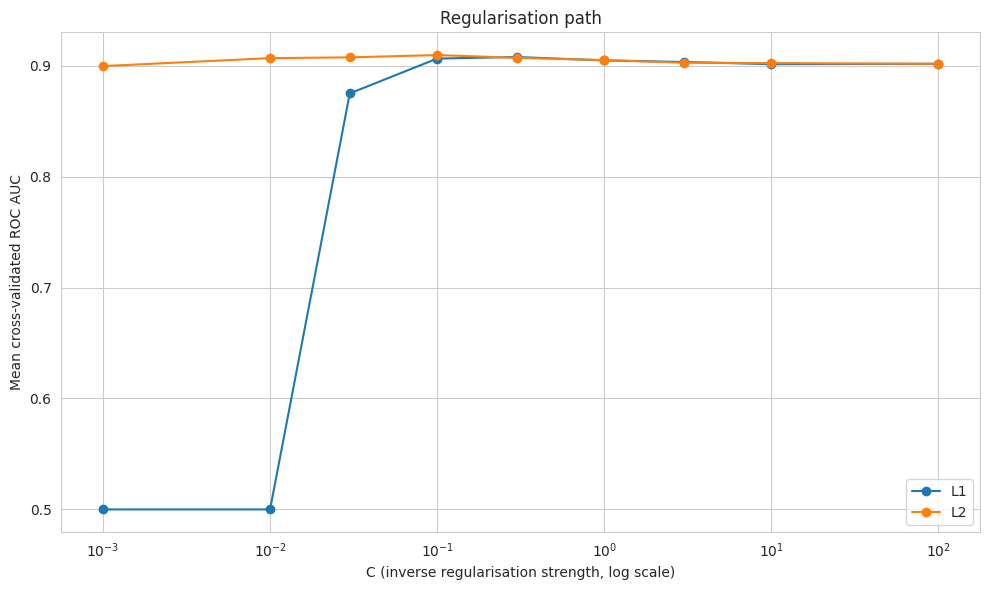

penalty     C  mean_cv_auc    std
     l2   0.1       0.9097 0.0172
     l1   0.3       0.9079 0.0144
     l2  0.03       0.9076 0.0184
     l2   0.3       0.9072 0.0203
     l2  0.01       0.9069 0.0199
     l1   0.1       0.9065 0.0187
     l2     1       0.9051 0.0189
     l1     1       0.9048 0.0162


In [38]:
res = pd.DataFrame(grid.cv_results_)[['param_model__penalty', 'param_model__C', 'mean_test_score', 'std_test_score']]
res.columns = ['penalty', 'C', 'mean_cv_auc', 'std']

fig, ax = plt.subplots(figsize=(10, 6))
for pen in ['l1', 'l2']:
    sub = res[res['penalty'] == pen].sort_values('C')
    ax.plot(sub['C'], sub['mean_cv_auc'], marker='o', label=pen.upper())
ax.set_xscale('log')
ax.set_xlabel('C (inverse regularisation strength, log scale)')
ax.set_ylabel('Mean cross-validated ROC AUC')
ax.set_title('Regularisation path')
ax.legend()
plt.tight_layout()
plt.show()

print(res.sort_values('mean_cv_auc', ascending=False).head(8).round(4).to_string(index=False))

## 7. Reading the coefficients

This is the part that justifies choosing logistic regression. Each coefficient is a change in log-odds, and exponentiating it gives an odds ratio: the multiplicative change in the odds of heart disease per one-unit change in the predictor.

One caveat makes the numbers below readable rather than misleading. The features were standardised inside the pipeline, so "one unit" means **one standard deviation** for the continuous predictors, not one year or one mmHg. For the binary and one-hot columns a standard deviation is not a natural unit either, so those odds ratios indicate direction and relative strength rather than a quantity a clinician would quote. Comparing magnitudes across features is exactly what standardisation makes valid, which is the trade being accepted.

In [39]:
best = grid.best_estimator_
coefs = best.named_steps['model'].coef_[0]

odds = pd.DataFrame({
    'coefficient': coefs,
    'odds_ratio': np.exp(coefs)
}, index=X.columns)
odds['abs_coef'] = odds['coefficient'].abs()
odds['direction'] = np.where(odds['coefficient'] > 0, 'increases risk', 'decreases risk')
odds = odds.sort_values('abs_coef', ascending=False).drop(columns=['abs_coef'])

print('Intercept:', round(float(best.named_steps['model'].intercept_[0]), 4))
print()
print('Coefficients per standard deviation, sorted by magnitude:')
print(odds.round(4).to_string())
print()
zeroed = (np.abs(coefs) < 1e-8).sum()
print('Coefficients driven exactly to zero by the penalty:', int(zeroed))

Intercept: -0.1622

Coefficients per standard deviation, sorted by magnitude:
           coefficient  odds_ratio       direction
ca              0.7016      2.0170  increases risk
thal            0.5470      1.7281  increases risk
cp_4            0.4809      1.6175  increases risk
sex             0.4614      1.5864  increases risk
slope_2         0.3393      1.4040  increases risk
thalach        -0.2831      0.7534  decreases risk
exang           0.2645      1.3028  increases risk
oldpeak         0.2046      1.2270  increases risk
trestbps        0.1923      1.2121  increases risk
restecg_2       0.1675      1.1824  increases risk
chol            0.1264      1.1347  increases risk
cp_3           -0.1260      0.8817  decreases risk
restecg_1      -0.0699      0.9325  decreases risk
fbs            -0.0431      0.9578  decreases risk
cp_2            0.0391      1.0398  increases risk
age             0.0219      1.0221  increases risk
slope_3         0.0009      1.0009  increases risk

Coe

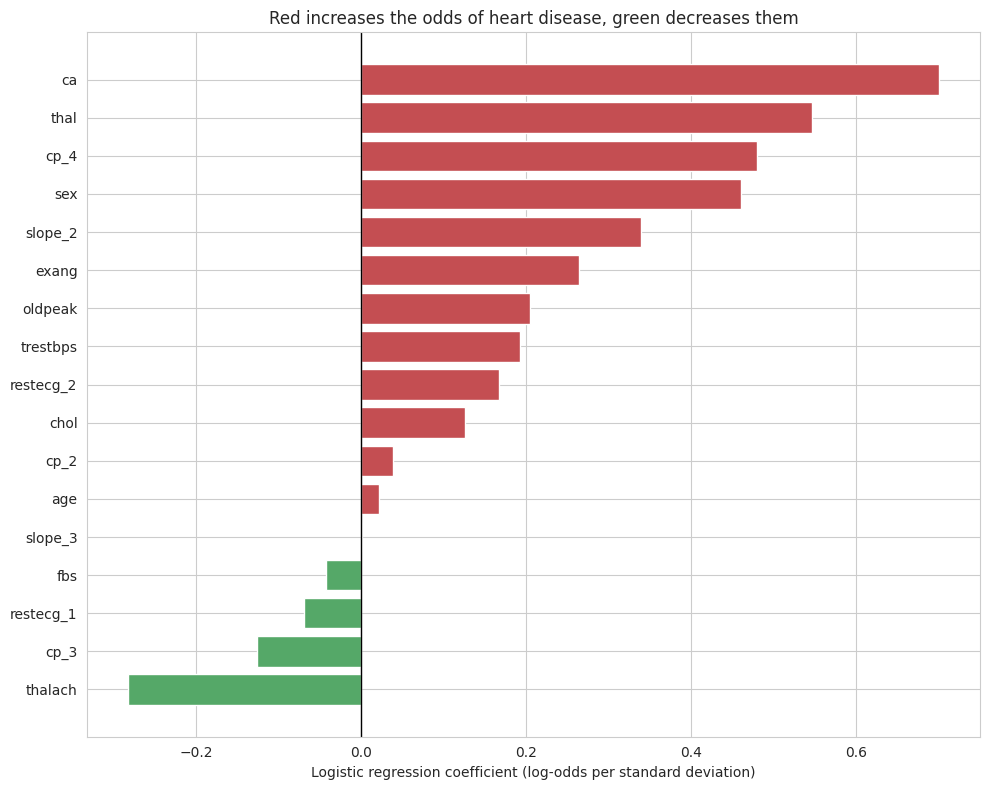

In [40]:
plot_df = odds.sort_values('coefficient')
colours = ['#55A868' if c < 0 else '#C44E52' for c in plot_df['coefficient']]

plt.figure(figsize=(10, 8))
plt.barh(plot_df.index, plot_df['coefficient'], color=colours)
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Logistic regression coefficient (log-odds per standard deviation)')
plt.title('Red increases the odds of heart disease, green decreases them')
plt.tight_layout()
plt.show()

## 8. Test set evaluation

In [41]:
y_pred = best.predict(X_test)
y_proba = best.predict_proba(X_test)[:, 1]

print('Accuracy :', round(accuracy_score(y_test, y_pred), 4))
print('Precision:', round(precision_score(y_test, y_pred), 4))
print('Recall   :', round(recall_score(y_test, y_pred), 4))
print('F1       :', round(f1_score(y_test, y_pred), 4))
print('ROC AUC  :', round(roc_auc_score(y_test, y_proba), 4))
print()
print('Majority-class baseline accuracy:', round(max(y_test.mean(), 1 - y_test.mean()), 4))

Accuracy : 0.8852
Precision: 0.8621
Recall   : 0.8929
F1       : 0.8772
ROC AUC  : 0.9502

Majority-class baseline accuracy: 0.541


In [42]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(pd.DataFrame(cm, index=['Actual: no disease', 'Actual: disease'],
                   columns=['Predicted: no disease', 'Predicted: disease']))
print()
print('False negatives (sick patients missed):', fn)
print('False positives (unnecessary follow-up):', fp)
print()
print(classification_report(y_test, y_pred, target_names=['No heart disease', 'Heart disease']))

                    Predicted: no disease  Predicted: disease
Actual: no disease                     29                   4
Actual: disease                         3                  25

False negatives (sick patients missed): 3
False positives (unnecessary follow-up): 4

                  precision    recall  f1-score   support

No heart disease       0.91      0.88      0.89        33
   Heart disease       0.86      0.89      0.88        28

        accuracy                           0.89        61
       macro avg       0.88      0.89      0.88        61
    weighted avg       0.89      0.89      0.89        61



## 9. Comparison against non-linear models

Logistic regression imposes a linear decision boundary in feature space. Whether that costs anything is an empirical question, so KNN and a random forest are fitted through the identical pipeline on the identical split. On a small, well-behaved tabular dataset the linear model is often competitive, and when it is, its interpretability is free.

In [43]:
candidates = {
    'Logistic regression (tuned)': best,
    'KNN (k=15, distance)': make_pipeline(KNeighborsClassifier(n_neighbors=15, weights='distance')),
    'Random forest': make_pipeline(RandomForestClassifier(n_estimators=400, random_state=RANDOM_STATE))
}

rows = []
curves = {}
for name, model in candidates.items():
    if name != 'Logistic regression (tuned)':
        model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc').mean()
    cmx = confusion_matrix(y_test, pred)
    rows.append({'model': name,
                 'cv_roc_auc': round(cv_auc, 4),
                 'test_accuracy': round(accuracy_score(y_test, pred), 4),
                 'test_recall': round(recall_score(y_test, pred), 4),
                 'test_roc_auc': round(roc_auc_score(y_test, proba), 4),
                 'false_negatives': int(cmx[1, 0])})
    curves[name] = roc_curve(y_test, proba)

comparison = pd.DataFrame(rows).set_index('model')
print(comparison.to_string())

                             cv_roc_auc  test_accuracy  test_recall  test_roc_auc  false_negatives
model                                                                                             
Logistic regression (tuned)      0.9097         0.8852       0.8929        0.9502                3
KNN (k=15, distance)             0.8829         0.9016       0.9286        0.9610                2
Random forest                    0.8918         0.9016       0.9643        0.9524                1


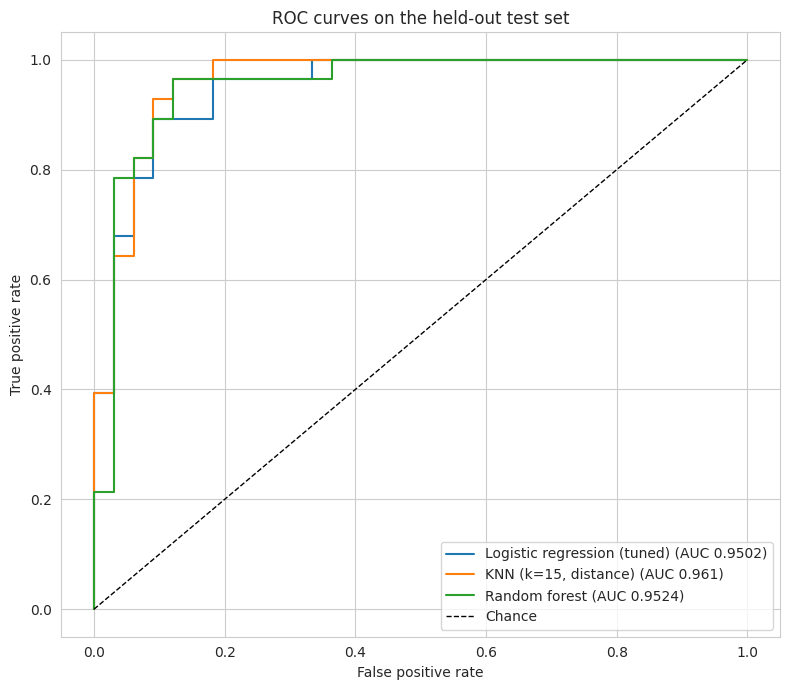

In [44]:
plt.figure(figsize=(8, 7))
for name, (fpr, tpr, _) in curves.items():
    plt.plot(fpr, tpr, label=name + ' (AUC ' + str(comparison.loc[name, 'test_roc_auc']) + ')')
plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Chance')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curves on the held-out test set')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### How much should a 61-patient test set be trusted?

The test metrics above rest on 61 patients, so a single reclassified patient moves accuracy by 1.6 points. Rather than present one split as though it settled anything, the cell below repeats the whole evaluation across 25 different stratified splits and reports the spread. The width of that distribution is the honest error bar on every test number in this notebook.

Test ROC AUC across 25 random stratified splits:
                             mean_auc     std     min     max
Logistic regression (tuned)    0.9116  0.0319  0.8366  0.9589
KNN (k=15, distance)           0.8917  0.0363  0.8090  0.9610
Random forest                  0.9000  0.0356  0.8149  0.9594


/tmp/ipykernel_41/2262244591.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([spread[n] for n in candidates], labels=[n.split(' (')[0] for n in candidates])


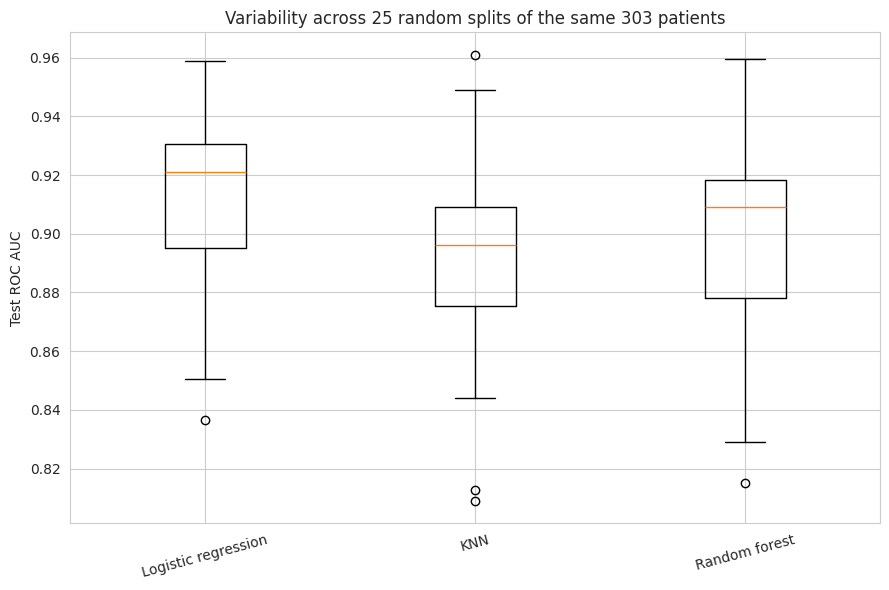

In [45]:
from sklearn.model_selection import StratifiedShuffleSplit

sss = StratifiedShuffleSplit(n_splits=25, test_size=0.2, random_state=RANDOM_STATE)
spread = {name: [] for name in candidates}

for tr_idx, te_idx in sss.split(X, y):
    Xtr, Xte = X.iloc[tr_idx], X.iloc[te_idx]
    ytr, yte = y.iloc[tr_idx], y.iloc[te_idx]
    for name, template in candidates.items():
        model = make_pipeline(LogisticRegression(max_iter=5000, C=grid.best_params_['model__C'],
                                                 penalty=grid.best_params_['model__penalty'],
                                                 solver=grid.best_params_['model__solver'],
                                                 random_state=RANDOM_STATE)) if 'Logistic' in name else template
        model.fit(Xtr, ytr)
        spread[name].append(roc_auc_score(yte, model.predict_proba(Xte)[:, 1]))

summary = pd.DataFrame({name: pd.Series(v).describe()[['mean', 'std', 'min', 'max']] for name, v in spread.items()}).T
summary.columns = ['mean_auc', 'std', 'min', 'max']
print('Test ROC AUC across 25 random stratified splits:')
print(summary.round(4).to_string())

plt.figure(figsize=(9, 6))
plt.boxplot([spread[n] for n in candidates], labels=[n.split(' (')[0] for n in candidates])
plt.ylabel('Test ROC AUC')
plt.title('Variability across 25 random splits of the same 303 patients')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 10. Conclusions

### The model

L2-penalised logistic regression, `C=0.1`, chosen from 18 configurations by cross-validated ROC AUC (0.9097). L1 was tested and not selected; no coefficients were driven to zero.

Held-out test set, 61 patients:

| Metric | Value |
|---|---|
| Accuracy | 0.8852 |
| Precision | 0.8621 |
| Recall | 0.8929 |
| F1 | 0.8772 |
| ROC AUC | 0.9502 |
| Majority-class baseline accuracy | 0.5410 |

Confusion matrix: 29 TN, 4 FP, 3 FN, 25 TP.

### What the coefficients say

Per standard deviation, sorted by magnitude:

| Feature | Coefficient | Odds ratio | Direction |
|---|---|---|---|
| `ca` (vessels on fluoroscopy) | +0.7016 | 2.02 | increases risk |
| `thal` (thalassemia scan) | +0.5470 | 1.73 | increases risk |
| `cp_4` (asymptomatic chest pain) | +0.4809 | 1.62 | increases risk |
| `sex` (male) | +0.4614 | 1.59 | increases risk |
| `slope_2` (flat ST segment) | +0.3393 | 1.40 | increases risk |
| `thalach` (max heart rate) | -0.2831 | 0.75 | decreases risk |
| `exang` (exercise angina) | +0.2645 | 1.30 | increases risk |
| `oldpeak` (ST depression) | +0.2046 | 1.23 | increases risk |
| `trestbps` (resting BP) | +0.1923 | 1.21 | increases risk |
| `chol` (cholesterol) | +0.1264 | 1.13 | increases risk |
| `age` | +0.0219 | 1.02 | negligible |

The number of major vessels showing blockage on fluoroscopy dominates, which is unsurprising given that it is closer to a direct observation of the disease than to a risk factor for it. A higher maximum heart rate achieved during exercise is protective, consistent with the exercise test measuring cardiac reserve.

**`age` carries essentially no coefficient**, at +0.0219 against +0.70 for `ca`. That is not evidence that age does not matter clinically; it is evidence that whatever age contributes is already captured by the exercise-test variables, which are downstream of it. A univariate model would show age as strongly predictive. This gap between marginal and conditional association is the standard reason not to read regression coefficients as rankings of clinical importance.

### The encoding investigation

The monotonicity check disagreed with the codebook in two places:

| Column | Codebook says | Disease rate across levels | Monotonic? |
|---|---|---|---|
| `cp` | nominal | 0.304, 0.180, 0.209, 0.729 | no |
| `restecg` | nominal | 0.371, 0.750, 0.541 | no |
| `slope` | **ordinal** | 0.254, 0.650, 0.571 | **no** |
| `thal` | **nominal** | 0.223, 0.667, 0.761 | **yes** |
| `ca` | ordinal count | 0.261, 0.677, 0.816, 0.850 | yes |

`slope` has a genuine ordering (upsloping, flat, downsloping) but the risk is not ordered along it: flat carries higher risk than downsloping, so one coefficient cannot represent it. `thal` is clinically unordered yet its risk happens to rise steadily across the arbitrary codes 3, 6 and 7. Reading the codebook alone would have got both wrong.

All four encodings were then fitted on identical folds, 5-fold cross-validation repeated 6 times:

| Treatment | Features | CV ROC AUC | std |
|---|---|---|---|
| A: all coded columns numeric | 13 | 0.9054 | 0.0361 |
| B: codebook nominal (`cp`, `restecg`, `thal`) | 17 | 0.9074 | 0.0320 |
| **C: empirically non-monotonic (`cp`, `restecg`, `slope`)** | 17 | **0.9090** | 0.0332 |
| D: every multi-level coded column | 18 | 0.9084 | 0.0328 |

The data-driven encoding does come out on top, but **the spread between best and worst is 0.0036 against a fold-to-fold standard deviation of 0.0335**, roughly nine times smaller than the noise. The honest conclusion is that on 303 rows this decision does not move the metric at all, and anyone reporting treatment C as an improvement over treatment A would be reporting noise.

That does not make the decision pointless. The coefficients above are the deliverable, and a coefficient on a non-monotonic column is not interpretable whatever it does to AUC. The encoding was chosen for readability, which is a defensible reason, rather than for performance, which the measurement does not support.

### Why a single test split should not be trusted

On the one 61-patient split, logistic regression looked like the worst of the three models:

| Model | CV ROC AUC | Test accuracy | Test recall | Test ROC AUC | Missed cases |
|---|---|---|---|---|---|
| Logistic regression (tuned) | 0.9097 | 0.8852 | 0.8929 | 0.9502 | 3 |
| KNN (k=15, distance) | 0.8829 | 0.9016 | 0.9286 | 0.9610 | 2 |
| Random forest | 0.8918 | 0.9016 | 0.9643 | 0.9524 | 1 |

Note that the cross-validation ranking and the test ranking are **exactly reversed**: logistic regression has the best CV AUC and the worst test AUC. That is the signal to stop and check rather than to pick a winner.

Repeating the entire evaluation across 25 random stratified splits:

| Model | Mean test AUC | std | min | max |
|---|---|---|---|---|
| **Logistic regression** | **0.9116** | **0.0319** | 0.8366 | 0.9589 |
| KNN (k=15, distance) | 0.8917 | 0.0363 | 0.8090 | 0.9610 |
| Random forest | 0.9000 | 0.0356 | 0.8149 | 0.9594 |

Logistic regression is in fact the **best** of the three on average, and the most stable. Each model's own range spans about 0.12 to 0.15 AUC, which is six to eight times the largest gap between models. The single-split ranking was noise, and reporting it as a result would have been wrong in both the ordering and the confidence.

The practical lesson is the one worth carrying out of this notebook: at n=303 a single 20% holdout cannot distinguish these models, and the linear model is competitive with both non-linear alternatives while also being the only one whose decision process can be inspected.

### Limitations

- **303 patients, 61 in the test set.** The 25-split ranges above are the real error bars on every test number here. Any comparison smaller than about 0.03 AUC is not measurable on this data.
- **Coefficients are per standard deviation**, because features were standardised inside the pipeline. For continuous predictors that is interpretable; for binary and one-hot columns a standard deviation is not a natural unit, so those values indicate direction and relative strength rather than a quantity worth quoting.
- **These are regularised coefficients**, shrunk toward zero by the L2 penalty at `C=0.1`. They are not maximum-likelihood estimates and should not be read as unbiased effect sizes. No standard errors, p-values or confidence intervals were computed; `statsmodels` would be the right tool for inference rather than prediction.
- **Collinearity among the exercise-test variables was not formally checked.** `oldpeak`, `slope`, `exang` and `thalach` all measure aspects of the same stress test. Regularisation stabilises the fit but redistributes coefficient mass among correlated predictors, which is a further reason to read individual magnitudes loosely.
- **This is observational data.** Every coefficient is an association. Nothing here supports a causal reading, and reverse causation is live: `ca` is measured by fluoroscopy, which is ordered because disease is already suspected.
- **The Cleveland data dates from 1988.** Population, measurement practice and diagnostic criteria have all moved since. None of these numbers estimate present-day performance.
- **Six values were imputed** (4 in `ca`, 2 in `thal`), too few to matter either way.
- **Nothing here is a diagnostic tool.** It is a classification exercise on a public teaching dataset.